# 2차시 (교사용) | 표준화와 K-means를 활용한 경북 시·군 군집 분석

**SW·AI 교과융합 수업: 지방소멸위험 데이터 기반의 K-means 군집 분석 PBL**

### 학습목표
- 두 점 사이의 거리와 중심(평균)의 개념을 활용하여 K-means 군집 분석의 원리를 설명할 수 있다.
- 표준화 전후의 군집 결과를 비교하여 표준화가 필요한 이유를 두 점 사이의 거리로 설명할 수 있다.

### 데이터
`gyeongbuk_2025.csv` : 경상북도 22개 시·군(22행 × 5열)

| 열 이름 | 의미 |
|---|---|
| 시군 | 시·군 이름 |
| 연도 | 기준 연도(2025) |
| 총인구 | 전체 인구(명) |
| 청년여성인구 | 20~39세 여성 인구(명) |
| 고령인구 | 65세 이상 인구(명) |

> 자료: 한국고용정보원(KEIS) 지방소멸위험지수 데이터(2025년)를 수업용으로 가공
> 지방소멸위험지수 = 20~39세 여성 인구 ÷ 65세 이상 인구 (0.5 미만이면 소멸위험지역)

**사용 방법:** 위에서부터 차례대로 셀을 실행하세요(Shift + Enter). `___` 부분은 빈칸입니다.

## 0. 준비하기

In [1]:
# ① 데이터가 있는 깃허브 저장소(저장소를 옮길 때만 수정)
REPO = 'choihyeongbae/local-extinction-kmeans'
BASE = f'https://raw.githubusercontent.com/{REPO}/main/data/'
# ② 그래프에서 한글이 보이도록 패키지 설치
!pip install -q koreanize-matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.cluster import KMeans

## 활동1. 두 점 사이의 거리와 중심
- 두 점 사이의 거리: $AB=\sqrt{(x_2-x_1)^2+(y_2-y_1)^2}$
- 여러 점의 중심: 각 좌표의 평균(두 점이면 선분의 중점 = 1:1 내분점)
- 거리가 가까울수록 두 지역의 특성이 비슷하다고 판단합니다.

In [2]:
import numpy as np
# 두 점 사이의 거리: √((x2-x1)² + (y2-y1)²)
def distance(p, q):
    dx, dy = q[0] - p[0], q[1] - p[1]
    return np.sqrt(dx**2 + dy**2)
A = np.array([1, 2])
B = np.array([4, 6])
print(f"A와 B 사이의 거리: {distance(A, B)}")

A와 B 사이의 거리: 5.0


In [3]:
# 세 점의 중심: x좌표의 평균, y좌표의 평균
points = np.array([[1, 2], [4, 6], [7, 1]])
center = points.mean(axis=0)
print(f"세 점의 중심: {center}")
# 두 점의 중심 = 선분 AB의 중점(1:1 내분점)
print(f"선분 AB의 중점: {(A + B) / 2}")

세 점의 중심: [4. 3.]
선분 AB의 중점: [2.5 4. ]


### 단위가 다른 실제 데이터의 거리 계산하기
상주시는 칠곡군과 문경시 중 어느 지역과 더 비슷할까요?

In [4]:
# (총인구, 고령인구비율)을 좌표로 표현
상주 = np.array([90996, 37.43])
칠곡 = np.array([105895, 21.10])
문경 = np.array([66259, 36.88])
d1 = distance(상주, 칠곡)
d2 = distance(상주, 문경)
print(f"상주-칠곡 거리: {d1:,.2f}")
print(f"상주-문경 거리: {d2:,.2f}")
# → 고령화 정도가 다른 칠곡군이 더 가까움!

상주-칠곡 거리: 14,899.01
상주-문경 거리: 24,737.00


## 활동2. 표준화(z-점수)의 이해
- $z = \dfrac{값 - 평균}{표준편차}$
- 표준화하면 모든 변수의 평균은 0, 표준편차는 1이 되어 단위와 크기의 차이가 사라집니다.
- `ddof=0`: 중학교에서 배운 표준편차(편차 제곱의 평균의 제곱근). pandas의 기본값(`ddof=1`)과 다르니 주의!

In [5]:
DATA_URL = BASE + 'gyeongbuk_2025.csv'
import pandas as pd
df = pd.read_csv(DATA_URL)
pop, old = df['총인구'], df['고령인구']
df['고령인구비율'] = old / pop * 100
df['소멸위험지수'] = df['청년여성인구'] / old
X = df[['총인구', '고령인구비율']]
# 두 변수의 범위와 표준편차 비교
print(X.describe().round(2))
# 표준화: (값 - 평균) ÷ 표준편차
# ddof=0: 중학교에서 배운 표준편차
X_scaled = (X - X.mean()) / X.std(ddof=0)
# 평균 → 0, 표준편차 → 1 확인
print(X_scaled.mean().abs().round(2))
print(X_scaled.std(ddof=0).round(2))

             총인구  고령인구비율
count      22.00   22.00
mean   114521.55   34.24
std    127989.89    9.24
min      9022.00   13.61
25%     34790.00   28.40
50%     60188.00   34.39
75%    127667.50   42.60
max    489898.00   48.44
총인구       0.0
고령인구비율    0.0
dtype: float64
총인구       1.0
고령인구비율    1.0
dtype: float64


In [6]:
# 표준화된 좌표(22행 2열 행렬)
s = X_scaled.values
names = list(df['시군'])
a = s[names.index('상주시')]
b = s[names.index('칠곡군')]
c = s[names.index('문경시')]
print(f"상주-칠곡: {distance(a, b):.3f}")
print(f"상주-문경: {distance(a, c):.3f}")
# → 표준화 후에는 문경시가 더 가까움!

상주-칠곡: 1.812
상주-문경: 0.207


## 활동3. K-means 군집 분석의 원리
1. 묶을 군집의 개수 K를 정하고, 중심점 K개를 임의로 정한다.
2. 각 지역을 가장 가까운(거리가 가장 짧은) 중심점의 군집에 배정한다.
3. 각 군집에 속한 점들의 좌표 평균으로 중심점을 새로 구한다.
4. 중심점이 더 이상 변하지 않을 때까지 2~3을 반복한다.

👉 각 지역은 **가장 가까운 중심점**에 배정되므로, 거리를 재는 방식(= 표준화 여부)이 군집 결과를 결정합니다.

## 활동4. 실습 1: 표준화 전후 K-means 결과 비교

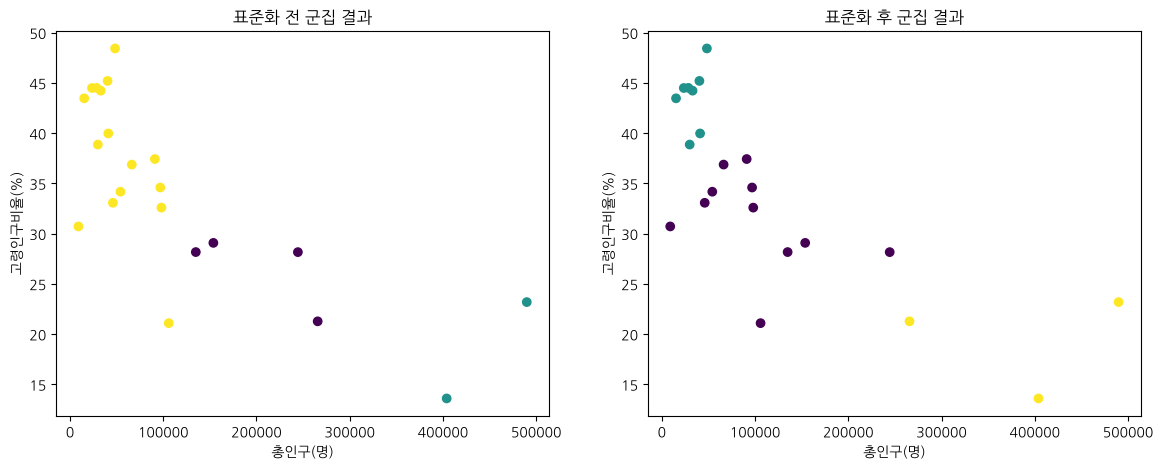

In [7]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import koreanize_matplotlib
# ① 표준화하지 않은 데이터로 군집 분석
km1 = KMeans(n_clusters=3, n_init=10,
             random_state=42)
df['군집_원본'] = km1.fit_predict(X)
# ② 표준화한 데이터로 군집 분석
km2 = KMeans(n_clusters=3, n_init=10,
             random_state=42)
df['군집_표준화'] = km2.fit_predict(X_scaled)
# 두 결과를 산점도로 나란히 비교
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
x, y = df['총인구'], df['고령인구비율']
ax[0].scatter(x, y, c=df['군집_원본'])
ax[0].set_title('표준화 전 군집 결과')
ax[1].scatter(x, y, c=df['군집_표준화'])
ax[1].set_title('표준화 후 군집 결과')
for a in ax:
    a.set_xlabel('총인구(명)')
    a.set_ylabel('고령인구비율(%)')
plt.show()

## 활동5. 실습 2: 군집별 특징 해석하기

In [8]:
# 표준화 후 군집별 평균 특성
summary = df.groupby('군집_표준화').agg(
    지역수=('시군', 'count'),
    평균총인구=('총인구', 'mean'),
    평균고령인구비율=('고령인구비율', 'mean'),
    평균소멸위험지수=('소멸위험지수', 'mean'))
print(summary.round(2))
# 군집별 소속 지역 확인
for k in range(3):
    g = list(df[df['군집_표준화'] == k]['시군'])
    print(f"군집 {k} ({len(g)}개): {g}")

        지역수      평균총인구  평균고령인구비율  평균소멸위험지수
군집_표준화                                    
0        11  100019.73     31.46      0.23
1         8   32470.38     43.65      0.11
2         3  386498.00     19.36      0.57
군집 0 (11개): ['경주시', '김천시', '안동시', '영주시', '영천시', '상주시', '문경시', '칠곡군', '예천군', '울진군', '울릉군']
군집 1 (8개): ['의성군', '청송군', '영양군', '영덕군', '청도군', '고령군', '성주군', '봉화군']
군집 2 (3개): ['포항시', '구미시', '경산시']


## 모둠활동지 1 | 표준화 전후 군집 결과 비교하기
### 단계 1: 표준화 직접 계산하기
표의 평균과 표준편차로 세 지역의 z 값을 계산해 표를 채워봅시다.

| 지역 | 총인구(명) | 고령인구비율(%) | z(총인구) | z(고령인구비율) |
|---|---|---|---|---|
| 상주시 | 90,996 | 37.43 | **-0.188** | **0.353** |
| 칠곡군 | 105,895 | 21.10 | **-0.069** | **-1.455** |
| 문경시 | 66,259 | 36.88 | **-0.386** | **0.292** |
| 경북 평균 | 114,522 | 34.24 | 0 | 0 |
| 경북 표준편차 | 125,047 | 9.03 | 1 | 1 |

### 단계 2: 코드 작성 (빈칸을 채우고 K를 바꾸어 실행)

In [9]:
DATA_URL = BASE + 'gyeongbuk_2025.csv'
import pandas as pd
from sklearn.cluster import KMeans
df = pd.read_csv(DATA_URL)
df['고령인구비율'] = df['고령인구'] / df['총인구'] * 100
X = df[['총인구', '고령인구비율']]

# 1. 표준화 (빈칸 '?'를 채워봅시다)
X_scaled = (X - X.mean()) / X.std(ddof=0)

# 2. K값을 바꾸어 가며 군집 분석 (K = 2, 3, 4)
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    print(f"\n=== K = {k} ===")
    for c in range(k):
        print(f"군집 {c}:", list(df['시군'][labels == c]))

# 3. 학생 코드 작성 부분
# (표준화하지 않은 X로도 군집 분석을 실행하여 결과를 비교해봅시다.)


=== K = 2 ===
군집 0: ['포항시', '경주시', '김천시', '안동시', '구미시', '경산시', '칠곡군']
군집 1: ['영주시', '영천시', '상주시', '문경시', '의성군', '청송군', '영양군', '영덕군', '청도군', '고령군', '성주군', '예천군', '봉화군', '울진군', '울릉군']

=== K = 3 ===
군집 0: ['경주시', '김천시', '안동시', '영주시', '영천시', '상주시', '문경시', '칠곡군', '예천군', '울진군', '울릉군']
군집 1: ['의성군', '청송군', '영양군', '영덕군', '청도군', '고령군', '성주군', '봉화군']
군집 2: ['포항시', '구미시', '경산시']

=== K = 4 ===
군집 0: ['영주시', '영천시', '상주시', '문경시', '고령군', '예천군', '울진군', '울릉군']
군집 1: ['경주시', '김천시', '안동시', '경산시', '칠곡군']
군집 2: ['포항시', '구미시']
군집 3: ['의성군', '청송군', '영양군', '영덕군', '청도군', '성주군', '봉화군']


In [10]:
# 3. (모범 예시) 표준화하지 않은 X로 군집 분석하여 비교
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    print(f"\n=== 표준화 전, K = {k} ===")
    for c in range(k):
        print(f"군집 {c}:", list(df['시군'][labels == c]))


=== 표준화 전, K = 2 ===
군집 0: ['김천시', '안동시', '영주시', '영천시', '상주시', '문경시', '의성군', '청송군', '영양군', '영덕군', '청도군', '고령군', '성주군', '칠곡군', '예천군', '봉화군', '울진군', '울릉군']
군집 1: ['포항시', '경주시', '구미시', '경산시']

=== 표준화 전, K = 3 ===
군집 0: ['경주시', '김천시', '안동시', '경산시']
군집 1: ['포항시', '구미시']
군집 2: ['영주시', '영천시', '상주시', '문경시', '의성군', '청송군', '영양군', '영덕군', '청도군', '고령군', '성주군', '칠곡군', '예천군', '봉화군', '울진군', '울릉군']

=== 표준화 전, K = 4 ===
군집 0: ['김천시', '안동시', '영주시', '영천시', '상주시', '칠곡군']
군집 1: ['포항시', '구미시']
군집 2: ['경주시', '경산시']
군집 3: ['문경시', '의성군', '청송군', '영양군', '영덕군', '청도군', '고령군', '성주군', '예천군', '봉화군', '울진군', '울릉군']


## 모둠활동지 2 | 우리 지역 맞춤형 인구 정책 제안하기
| 군집 | 지역 수 | 평균 총인구(명) | 평균 고령인구비율(%) | 평균 소멸위험지수 | 소속 지역 |
|---|---|---|---|---|---|
| A | 3 | 386,498 | 19.36 | 0.57 | 포항·구미·경산 |
| B | 11 | 100,020 | 31.46 | 0.23 | 경주·김천·안동·영주·영천·상주·문경·칠곡·예천·울진·울릉 |
| C | 8 | 32,470 | 43.65 | 0.11 | 의성·청송·영양·영덕·청도·고령·성주·봉화 |

※ 코드의 군집 번호(0~2)는 실행 환경에 따라 다를 수 있으니 소속 지역으로 A~C와 대응시키세요.

In [11]:
DATA_URL = BASE + 'gyeongbuk_2025.csv'
import pandas as pd
from sklearn.cluster import KMeans
df = pd.read_csv(DATA_URL)
df['고령인구비율'] = df['고령인구'] / df['총인구'] * 100
df['소멸위험지수'] = df['청년여성인구'] / df['고령인구']
X = df[['총인구', '고령인구비율']]
X_scaled = (X - X.mean()) / X.std(ddof=0)
km = KMeans(n_clusters=3, n_init=10, random_state=42)
df['군집'] = km.fit_predict(X_scaled)
# 군집별 평균 특성
cols = ['총인구', '고령인구비율', '소멸위험지수']
print(df.groupby('군집')[cols].mean().round(2))
# 우리 지역(포항시)과 같은 군집에 속한 지역 찾기
my_cluster = df[df['시군'] == '포항시']['군집'].values[0]
same = df[df['군집'] == my_cluster]['시군']
print(f"\n포항시와 같은 유형의 지역: {list(same)}")
# 군집별 정책 제안 (모둠 토의 후 '?'에 작성)
policy = {0: '생활권 중심도시 기능 강화, 공공의료·대중교통 확충',
          1: '방문 의료·돌봄 서비스, 공공시설 공동 이용, 귀농·귀촌 지원',
          2: '청년 주거·보육 지원, 산업 연계 일자리 유지'}  # 예시(번호는 실행 결과로 확인)
print("\n=== 군집별 맞춤형 인구 정책 제안 ===")
for c in range(3):
    names = list(df[df['군집'] == c]['시군'])
    print(f"[군집 {c}] {names}")
    print(f"  → 정책: {policy[c]}")

          총인구  고령인구비율  소멸위험지수
군집                           
0   100019.73   31.46    0.23
1    32470.38   43.65    0.11
2   386498.00   19.36    0.57

포항시와 같은 유형의 지역: ['포항시', '구미시', '경산시']

=== 군집별 맞춤형 인구 정책 제안 ===
[군집 0] ['경주시', '김천시', '안동시', '영주시', '영천시', '상주시', '문경시', '칠곡군', '예천군', '울진군', '울릉군']
  → 정책: 생활권 중심도시 기능 강화, 공공의료·대중교통 확충
[군집 1] ['의성군', '청송군', '영양군', '영덕군', '청도군', '고령군', '성주군', '봉화군']
  → 정책: 방문 의료·돌봄 서비스, 공공시설 공동 이용, 귀농·귀촌 지원
[군집 2] ['포항시', '구미시', '경산시']
  → 정책: 청년 주거·보육 지원, 산업 연계 일자리 유지


## 생각 정리하기

**Q1.** [6-1 단계 1] 세 지역의 z 값을 계산하고, 상주시와 다른 두 지역 사이의 거리를 표준화 전과 후로 비교해봅시다.

> **모범답안** z 값(총인구, 고령인구비율)은 상주시 (-0.188, 0.353), 칠곡군 (-0.069, -1.455), 문경시 (-0.386, 0.292)입니다. 표준화 전 거리는 상주–칠곡 14,899.01, 상주–문경 24,737.00으로 칠곡군이 더 가깝지만, 표준화 후에는 상주–칠곡 1.812, 상주–문경 0.207로 문경시가 훨씬 가깝습니다. 표준화 전에는 총인구 차이가 거리를 거의 전부 결정하기 때문입니다.

**Q2.** [6-1 단계 2] 빈칸에 들어갈 코드를 쓰고, K를 2, 3, 4로 바꾸었을 때 결과가 어떻게 달라지는지 설명해봅시다.

> **모범답안** 빈칸에는 X.mean()과 X.std(ddof=0)이 들어갑니다. K=2에서는 포항·경주·김천·안동·구미·경산·칠곡의 7곳과 나머지 15곳으로 나뉘고, K=3에서는 포항·구미·경산이 따로 분리됩니다. K=4에서는 포항·구미가 따로 묶이고 의성·청송 등 7곳의 초고령 지역이 분리됩니다. K가 커질수록 더 세밀하게 나뉘지만 해석이 어려워지므로, 정책 제안 목적에서는 특징이 뚜렷한 K=3이 적절하다고 볼 수 있습니다. 표준화하지 않은 X를 사용하면 총인구 크기 순서로만 나뉩니다.

**Q3.** [6-2] 군집 A~C에 이름을 붙이고, 군집별 맞춤형 인구 정책을 제안해봅시다.

> **모범답안** (예시) 군집 A ‘청년 산업도시형’(포항·구미·경산): 평균 고령인구비율 19.36%로 가장 낮고 평균 소멸위험지수 0.57로 가장 높음 → 청년 정주를 위한 주거·보육 지원, 산업 연계 일자리 유지. 군집 B ‘고령화 진행 중소도시형’(11곳): 고령인구비율 31.46%, 지수 0.23 → 생활권 중심도시 기능 강화, 공공의료·대중교통 확충. 군집 C ‘초고령 농촌형’(8곳): 고령인구비율 43.65%, 지수 0.11 → 방문 의료·돌봄 서비스, 인근 시·군과 공공시설 공동 이용, 귀농·귀촌 지원.(모둠별 자유 응답)